# 06 — DDPM | Fashion-MNIST (Simple)

**Denoising Diffusion Probabilistic Model (DDPM)**, sesuai tugas studi komparatif. Model belajar **memprediksi noise** pada citra Fashion-MNIST, kemudian menghasilkan gambar baru melalui reverse diffusion berulang.

**Output untuk PDF:** FID-2048, latency untuk **64 sampel**, waktu training/epoch, **Figur 2** (16 sampel generatif), **Figur 5** (loss prediksi noise dan denoising trajectory), hasil CSV, dan checkpoint/resume.

**Aturan bersama:** Fashion-MNIST 70.000 gambar, **split 80/10/10** (file split yang sama), batch 128, seed 42. Percobaan awal **15 epoch** dengan **100 diffusion steps** untuk mengurangi biaya komputasi. Tambah epoch/steps jika kualitas gambar belum memadai. **GPU sangat disarankan.**

> DDPM berbeda dari AE/VAE/GAN: **tidak memiliki latent encoder untuk rekonstruksi langsung**, sehingga Test MSE/PSNR/SSIM pada tabel komparasi diberi **N/A**, dan latent dimension pada tabel merujuk ke ukuran citra noise (784).

## 1. Setup

Jika dependensi belum terpasang, jalankan sekali (di cell terpisah):

`%pip install -q torch torchvision numpy pandas matplotlib "torchmetrics[image]" torch-fidelity`

In [1]:
from pathlib import Path
import math, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import ConcatDataset, Subset, DataLoader
from torchvision import datasets, transforms

SEED, BATCH, EPOCHS, TIMESTEPS = 42, 128, 15, 100
LR, FID_SAMPLES = 2e-4, 2048
RESUME = False                       # True: lanjut dari checkpoint terakhir
RUN_FID = True                      # False hanya untuk debugging, FID akan N/A
OUT = Path('outputs/ddpm')
OUT.mkdir(parents=True, exist_ok=True)
SPLIT_FILE = Path('fashion_mnist_split_seed42.npz')
LAST, BEST = OUT / 'ddpm_last.pt', OUT / 'ddpm_best.pt'

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## 2. Fashion-MNIST — dataset split identik dengan model sebelumnya

Data asli berada pada **[0, 1]**. Untuk diffusion, training mengubahnya ke **[-1, 1]**; saat menampilkan dan menghitung FID, keluaran dikembalikan ke **[0, 1]**.

In [2]:
full = ConcatDataset([
    datasets.FashionMNIST('data', train=True, download=True, transform=transforms.ToTensor()),
    datasets.FashionMNIST('data', train=False, download=True, transform=transforms.ToTensor()),
])
if SPLIT_FILE.exists():
    with np.load(SPLIT_FILE) as split:
        train_idx, val_idx, test_idx = split['train_idx'], split['val_idx'], split['test_idx']
else:
    idx = torch.randperm(len(full), generator=torch.Generator().manual_seed(SEED)).numpy()
    train_idx, val_idx, test_idx = idx[:56000], idx[56000:63000], idx[63000:]
    np.savez_compressed(SPLIT_FILE, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)

assert (len(train_idx), len(val_idx), len(test_idx)) == (56000, 7000, 7000)
assert len(np.unique(np.r_[train_idx, val_idx, test_idx])) == len(full)
train_set, val_set, test_set = [Subset(full, a.tolist()) for a in (train_idx, val_idx, test_idx)]
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_set, batch_size=BATCH, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH, shuffle=False)
print('Train / Val / Test:', len(train_set), len(val_set), len(test_set))

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.74MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 27.1MB/s]


Train / Val / Test: 56000 7000 7000


## 3. Noise schedule + model U-Net kecil

Forward diffusion: $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$, dengan $\epsilon\sim\mathcal{N}(0,I)$.

Objective: $\mathcal{L}=\mathbb{E}_{x_0,t,\epsilon}\lVert\epsilon-\epsilon_\theta(x_t,t)\rVert_2^2$.

Model menggunakan **U-Net sederhana** dengan convolution, skip connection, dan sinusoidal time embeddings. **Cosine noise schedule** membuat derau akhir mendekati Gaussian murni walaupun hanya memakai 100 step.

In [4]:
# Cosine schedule (betas[t], alphas[t], alpha_bars[t])
s = 0.008
steps = torch.linspace(0, TIMESTEPS, TIMESTEPS + 1, dtype=torch.float64)
abar = torch.cos((steps / TIMESTEPS + s) / (1 + s) * math.pi / 2).square()
abar = abar / abar[0]
betas = (1 - abar[1:] / abar[:-1]).clamp(1e-4, 0.999).float().to(device)
alphas = 1 - betas
alpha_bars       = alphas.cumprod(0)
alpha_bars_prev  = torch.cat([torch.ones(1, device=device), alpha_bars[:-1]])
posterior_var    = betas * (1 - alpha_bars_prev) / (1 - alpha_bars)

class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.n1, self.n2 = nn.GroupNorm(8, cout), nn.GroupNorm(8, cout)
        self.t_proj = nn.Linear(128, cout)

    def forward(self, x, emb):
        h = F.silu(self.n1(self.c1(x)))
        h = h + self.t_proj(emb)[:, :, None, None]
        return F.silu(self.n2(self.c2(h)))

class TinyUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.t_mlp = nn.Sequential(nn.Linear(64, 128), nn.SiLU(), nn.Linear(128, 128))
        self.d1, self.d2 = ConvBlock(1, 32), ConvBlock(32, 64)
        self.mid = ConvBlock(64, 128)
        self.u2, self.u1 = ConvBlock(128 + 64, 64), ConvBlock(64 + 32, 32)
        self.out = nn.Conv2d(32, 1, 1)

    def forward(self, x, t):
        freq = torch.exp(-math.log(10000) * torch.arange(32, device=t.device) / 31)
        angles = t.float()[:, None] * freq[None, :]
        emb = self.t_mlp(torch.cat([angles.sin(), angles.cos()], dim=1))
        a = self.d1(x, emb)                         # 28 × 28
        b = self.d2(F.avg_pool2d(a, 2), emb)       # 14 × 14
        h = self.mid(F.avg_pool2d(b, 2), emb)      # 7 × 7
        h = self.u2(torch.cat([F.interpolate(h, scale_factor=2), b], dim=1), emb)
        h = self.u1(torch.cat([F.interpolate(h, scale_factor=2), a], dim=1), emb)
        return self.out(h)                         # noise prediction: 1 × 28 × 28

model = TinyUNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
num_params = sum(p.numel() for p in model.parameters())
print('Parameters:', f'{num_params:,}')
print('Model output:', tuple(model(torch.randn(2,1,28,28,device=device),
                                   torch.randint(TIMESTEPS,(2,),device=device)).shape))

Parameters: 538,369
Model output: (2, 1, 28, 28)


## 4. Training dan validation

Untuk setiap batch: pilih timestep acak, tambahkan noise ke gambar, dan minimalkan MSE antara **noise asli** dan **noise prediksi**. Simpan **checkpoint setiap epoch** agar bisa dilanjutkan, serta bobot dari validation loss terbaik.

In [5]:
def sync():
    if device.type == 'cuda': torch.cuda.synchronize()
    elif device.type == 'mps': torch.mps.synchronize()

def run_epoch(loader, training):
    model.train(training)
    total = n_total = 0
    with torch.set_grad_enabled(training):
        for x, _ in loader:
            x = x.to(device) * 2 - 1
            t = torch.randint(0, TIMESTEPS, (len(x),), device=device)
            noise = torch.randn_like(x)
            x_t = alpha_bars[t, None, None, None].sqrt() * x + \
                  (1 - alpha_bars[t, None, None, None]).sqrt() * noise
            if training: optimizer.zero_grad()
            loss = F.mse_loss(model(x_t, t), noise)
            if training:
                loss.backward()
                optimizer.step()
            total += loss.item() * len(x)
            n_total += len(x)
    return total / n_total

history, start_epoch, best_val = [], 1, float('inf')
if RESUME and LAST.exists():
    ckpt = torch.load(LAST, map_location=device, weights_only=False) # checkpoint buatan sendiri
    model.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['optimizer'])
    history, start_epoch, best_val = ckpt['history'], ckpt['epoch']+1, ckpt['best_val']
    print('Resume dari epoch:', start_epoch)

for epoch in range(start_epoch, EPOCHS + 1):
    sync(); start = time.perf_counter()
    train_loss = run_epoch(train_loader, True)
    sync(); seconds = time.perf_counter() - start
    val_loss = run_epoch(val_loader, False)
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                        training_time_s=seconds))
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), BEST)
    torch.save(dict(epoch=epoch, model=model.state_dict(), optimizer=optimizer.state_dict(),
                    history=history, best_val=best_val, timesteps=TIMESTEPS), LAST)
    print(f'Epoch {epoch:02d} | Train {train_loss:.4f} | Val {val_loss:.4f} | {seconds:.1f}s')

if not history:
    raise RuntimeError('Belum ada history training. Pastikan EPOCHS >= 1.')
history_df = pd.DataFrame(history)
history_df.to_csv(OUT / 'ddpm_history.csv', index=False)
model.load_state_dict(torch.load(BEST, map_location=device, weights_only=True))
model.eval()
print('Best validation loss:', best_val)

Epoch 01 | Train 0.1625 | Val 0.1037 | 17.3s
Epoch 02 | Train 0.1001 | Val 0.0941 | 17.3s
Epoch 03 | Train 0.0915 | Val 0.0873 | 17.1s
Epoch 04 | Train 0.0864 | Val 0.0875 | 17.1s
Epoch 05 | Train 0.0840 | Val 0.0834 | 17.4s
Epoch 06 | Train 0.0820 | Val 0.0802 | 17.3s
Epoch 07 | Train 0.0807 | Val 0.0784 | 17.6s
Epoch 08 | Train 0.0782 | Val 0.0794 | 17.2s
Epoch 09 | Train 0.0782 | Val 0.0783 | 17.5s
Epoch 10 | Train 0.0766 | Val 0.0764 | 17.3s
Epoch 11 | Train 0.0760 | Val 0.0766 | 17.6s
Epoch 12 | Train 0.0751 | Val 0.0755 | 17.3s
Epoch 13 | Train 0.0746 | Val 0.0732 | 17.6s
Epoch 14 | Train 0.0755 | Val 0.0739 | 17.3s
Epoch 15 | Train 0.0741 | Val 0.0757 | 17.4s
Best validation loss: 0.07323303693532944


## 5. Reverse diffusion — menghasilkan citra baru

Dari noise Gaussian $x_T$, lakukan denoising berulang sampai $x_0$. Metode di bawah adalah **ancestral DDPM sampling** (bukan DDIM). Untuk laporan, ambil beberapa snapshot pada tahap reverse diffusion.

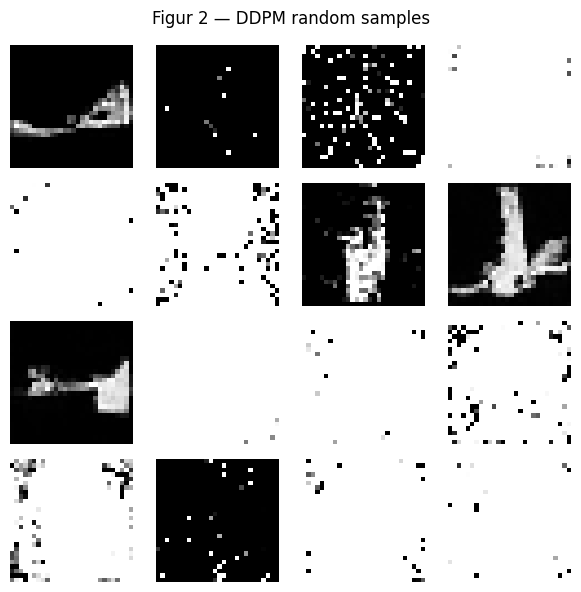

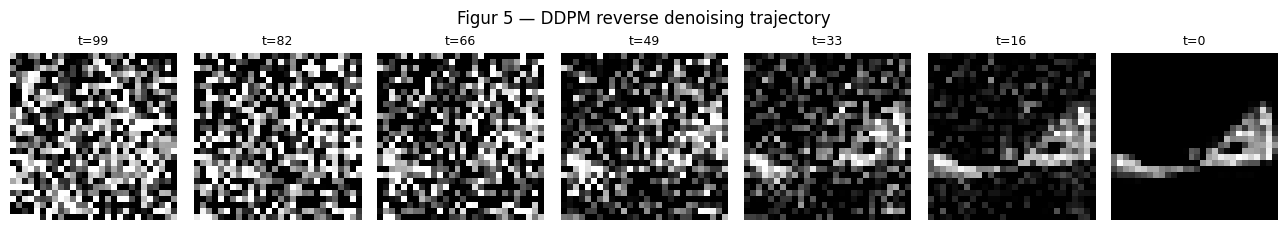

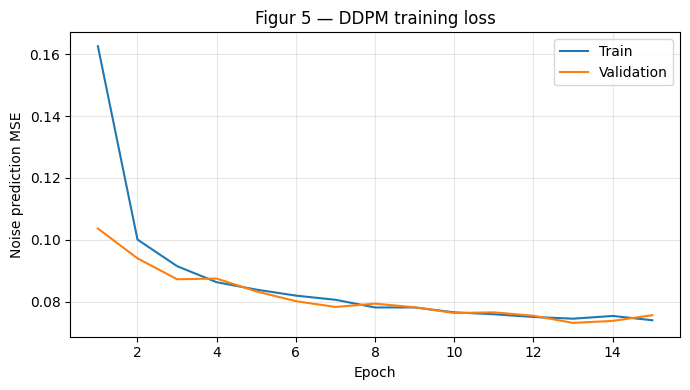

In [6]:
@torch.inference_mode()
def sample(n, save_steps=False, initial_noise=None):
    model.eval()
    x = torch.randn(n, 1, 28, 28, device=device) if initial_noise is None \
        else initial_noise.clone()
    snapshots = []
    keep = set(np.linspace(TIMESTEPS - 1, 0, 7, dtype=int).tolist())
    for step in reversed(range(TIMESTEPS)):
        t = torch.full((n,), step, device=device, dtype=torch.long)
        eps = model(x, t)
        mean = (x - betas[step] / (1 - alpha_bars[step]).sqrt() * eps) / alphas[step].sqrt()
        x = mean + posterior_var[step].sqrt() * torch.randn_like(x) if step > 0 else mean
        if save_steps and step in keep:
            snapshots.append((step, ((x.clamp(-1, 1) + 1) / 2).cpu()))
    images = (x.clamp(-1, 1) + 1) / 2  # [0, 1]
    return (images, snapshots) if save_steps else images

# Figur 2: 16 gambar generatif, kisi 4 × 4
samples, trajectory = sample(16, save_steps=True)
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, img in zip(axes.flat, samples.cpu()):
    ax.imshow(img[0], cmap='gray', vmin=0, vmax=1); ax.axis('off')
fig.suptitle('Figur 2 — DDPM random samples')
plt.tight_layout(); plt.savefig(OUT / 'figure2_ddpm_samples.png', dpi=200); plt.show()

# Figur 5: denoising trajectory untuk satu gambar (snapshot awal sampai akhir)
fig, axes = plt.subplots(1, len(trajectory), figsize=(13, 2.3))
for ax, (step, imgs) in zip(axes, trajectory):
    ax.imshow(imgs[0, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f't={step}', fontsize=9); ax.axis('off')
fig.suptitle('Figur 5 — DDPM reverse denoising trajectory')
plt.tight_layout(); plt.savefig(OUT / 'figure5_ddpm_denoising.png', dpi=200); plt.show()

# Figur 5: training / validation noise prediction MSE
plt.figure(figsize=(7, 4))
plt.plot(history_df.epoch, history_df.train_loss, label='Train')
plt.plot(history_df.epoch, history_df.val_loss, label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Noise prediction MSE')
plt.title('Figur 5 — DDPM training loss'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / 'figure5_ddpm_loss.png', dpi=200); plt.show()

## 6. Inference latency — batch 64

Ukur **keseluruhan 100 langkah reverse diffusion**, bukan hanya satu forward pass U-Net. Untuk menghemat waktu, gunakan 1 warmup + 3 pengulangan (GAN sebelumnya 10 + 30; jumlah pengulangan berbeda, namun ukuran batch tetap sama). Ubah `LATENCY_RUNS` jika ingin estimasi lebih presisi.

In [7]:
LATENCY_RUNS = 3
initial = torch.randn(64, 1, 28, 28, device=device)
_ = sample(64, initial_noise=initial)  # warmup
sync()
timings = []
for _ in range(LATENCY_RUNS):
    sync(); start = time.perf_counter()
    _ = sample(64, initial_noise=initial)
    sync(); timings.append((time.perf_counter() - start) * 1000)
latency = float(np.mean(timings))
print(f'Latency sampling {TIMESTEPS} step / batch 64: {latency:.2f} ± {np.std(timings):.2f} ms')

Latency sampling 100 step / batch 64: 475.92 ± 0.76 ms


## 7. FID — Inception-2048 (test set vs generated samples)

Gunakan **2048 gambar asli** dari test set dan **2048 sampel DDPM**; pengaturan ini sama dengan GAN, DCGAN, VAE sebelumnya. Semua gambar grayscale disalin ke **3 kanal** agar kompatibel dengan Inception. Perhitungan FID dapat memakan waktu lama karena DDPM harus melakukan 100 langkah untuk **setiap batch**.

> Perlu `torchmetrics[image]`, `torch-fidelity`, dan internet pada pertama kali mengunduh bobot Inception. Jangan melaporkan nilai FID jika penghitungan belum berhasil.

In [8]:
%pip install -q "torchmetrics[image]"

In [9]:
fid_score, seen = float('nan'), 0
if RUN_FID:
    from torchmetrics.image.fid import FrechetInceptionDistance
    fid_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    metric = FrechetInceptionDistance(feature=2048, normalize=True).to(fid_device)
    metric.set_dtype(torch.float64)
    fid_loader = DataLoader(test_set, batch_size=64, shuffle=False)
    for real, _ in fid_loader:
        if seen >= FID_SAMPLES: break
        real = real[:FID_SAMPLES-seen]
        fake = sample(len(real)).to(fid_device)
        metric.update(real.to(fid_device).repeat(1, 3, 1, 1), real=True)
        metric.update(fake.repeat(1, 3, 1, 1), real=False)
        seen += len(real)
        if seen % 512 == 0: print('FID progress:', seen, '/', FID_SAMPLES)
    fid_score = float(metric.compute().item())
    print(f'FID-2048 ({seen} real + {seen} generated): {fid_score:.3f}')
else:
    print('FID dilewati untuk debugging; hasil FID pada CSV akan kosong (NaN).')

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 130MB/s]


FID progress: 512 / 2048
FID progress: 1024 / 2048
FID progress: 1536 / 2048
FID progress: 2048 / 2048
FID-2048 (2048 real + 2048 generated): 238.519


## 8. Ekspor metrik untuk final comparison

Tabel memakai nama kolom yang selaras dengan notebook GAN/DCGAN. MSE, PSNR, SSIM adalah **N/A**, karena DDPM ini tidak memiliki jalur rekonstruksi citra yang terpasangkan sebagaimana AE/VAE. Catat jumlah diffusion steps saat membandingkan kualitas dan latency.

In [10]:
result = pd.DataFrame([{
    'model': 'DDPM', 'dataset': 'Fashion-MNIST', 'seed': SEED,
    'train_size': len(train_set), 'val_size': len(val_set), 'test_size': len(test_set),
    'latent_dim': 28*28, 'batch_size': BATCH, 'epochs': int(history_df.epoch.iloc[-1]),
    'num_parameters': num_params, 'learning_rate': LR,
    'diffusion_steps': TIMESTEPS, 'noise_schedule': 'cosine',
    'training_time_epoch_s_mean': float(history_df.training_time_s.mean()),
    'inference_latency_batch64_ms': latency,
    'test_mse': float('nan'), 'test_psnr_db': float('nan'), 'test_ssim': float('nan'),
    'fid': fid_score, 'fid_features': 2048, 'fid_samples': seen,
    'best_val_loss': best_val, 'device': str(device)
}])
result.to_csv(OUT / 'ddpm_metrics.csv', index=False)
print(result.T.to_string(header=False))
print('Output:', OUT.resolve())

model                                  DDPM
dataset                       Fashion-MNIST
seed                                     42
train_size                            56000
val_size                               7000
test_size                              7000
latent_dim                              784
batch_size                              128
epochs                                   15
num_parameters                       538369
learning_rate                        0.0002
diffusion_steps                         100
noise_schedule                       cosine
training_time_epoch_s_mean        17.342456
inference_latency_batch64_ms     475.923382
test_mse                                NaN
test_psnr_db                            NaN
test_ssim                               NaN
fid                              238.518589
fid_features                           2048
fid_samples                            2048
best_val_loss                      0.073233
device                          

In [11]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r "/content/outputs/ddpm" "/content/drive/MyDrive/[CN] Colab Notebooks/[CV] Computer Vision/DCGANAE: All Experiments/Results"


Mounted at /content/drive


### File yang dihasilkan

- `outputs/ddpm/ddpm_last.pt`: checkpoint (model, optimizer, history) setiap epoch; dapat **resume**.
- `outputs/ddpm/ddpm_best.pt`: bobot dengan validation noise prediction loss terbaik.
- `outputs/ddpm/ddpm_history.csv`: train/validation loss dan durasi epoch.
- `outputs/ddpm/ddpm_metrics.csv`: FID, latency per 64, waktu training, konfigurasi diffusion.
- `outputs/ddpm/figure2_ddpm_samples.png`: kisi 4×4 gambar acak.
- `outputs/ddpm/figure5_ddpm_denoising.png`: proses noise menjadi gambar.
- `outputs/ddpm/figure5_ddpm_loss.png`: kurva loss.

**Untuk Q3:** jelaskan bahwa training DDPM menggunakan supervised noise prediction, biasanya lebih stabil daripada min-max GAN, namun inference **jauh lebih mahal** karena iterative denoising. **Untuk Q6:** bandingkan FID dan latency aktual DDPM dengan DCGAN. Hasil nyata bergantung pada komputasi, epoch, dan tuning; jangan mengasumsikan DDPM pasti menang pada eksperimen kecil ini.